# Libraries

In [3]:
import netCDF4 as nc
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
# from karateclub import Graph2Vec
import os
import pandas as pd

In [ ]:
pip install networkx


## installed libraries

In [2]:
!pip install numpy
!pip install karateclub


Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 26.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.8/16.8 MB 16.3 MB/s  0:00:01m0:00:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.5/11.5 MB 72.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.6/27.6 MB 33.4 MB/s  0:00:006m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 66.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 69.2 MB/s  0:00:00
  Created wheel for karateclub: filename=karateclub-1.3

# Seismic Savanna out-of-the-box dataset

## Data read

In [4]:

dset = nc.Dataset("PROJECT/dset_allspec_150_chunks_clean.nc","r")
# time_series = dset["chunk"][1,0,:]
# len(time_series)

In [5]:
# dset.close()

## check dimension

In [6]:
print(dset.dimensions.keys())
for dim in dset.dimensions.values():
    print(dim)

dict_keys(['time', 'traces', 'comp', 'side'])
"<class 'netCDF4.Dimension'>": name = 'time', size = 2048
"<class 'netCDF4.Dimension'>": name = 'traces', size = 70637
"<class 'netCDF4.Dimension'>": name = 'comp', size = 3
"<class 'netCDF4.Dimension'>": name = 'side', size = 128


## check variables

In [7]:
print(dset.variables.keys())
for var in dset.variables:
    print(f"Variable: {var}, shape:{dset.variables[var].shape} , Data Type:{dset.variables[var].dtype}")

dict_keys(['chunk', 'class', 'distance', 'seis', 'image'])
Variable: chunk, shape:(70637, 3, 2048) , Data Type:float32
Variable: class, shape:(70637,) , Data Type:int64
Variable: distance, shape:(70637,) , Data Type:float32
Variable: seis, shape:(70637,) , Data Type:int64
Variable: image, shape:(70637, 128, 128, 3) , Data Type:int64


## Extract First Data Entry 

In [8]:
print("first data entry:")

for var_name, var in dset.variables.items():
    if var.ndim > 0:
        first_data = var[0]
        print(f"variable:{var_name}")
        print("shape:",first_data.shape)
        print("data sample:", first_data)
        

first data entry:
variable:chunk
shape: (3, 2048)
data sample: [[-1.62505986e-09  2.56003507e-09 -2.65518690e-10 ... -3.76963044e-12
  -1.31978692e-10 -5.88313842e-11]
 [-1.38451761e-09  2.78957835e-09 -2.56962562e-10 ...  3.24218395e-11
  -2.44652631e-10 -5.94519017e-11]
 [-1.30287237e-09  2.86068746e-09 -2.69089112e-10 ... -2.17682289e-10
  -1.56658486e-12  1.13556005e-10]]
variable:class
shape: ()
data sample: 1
variable:distance
shape: ()
data sample: 145.20766
variable:seis
shape: ()
data sample: 4
variable:image
shape: (128, 128, 3)
data sample: [[[  0   0   0]
  [  3   3   3]
  [ 89  89  89]
  ...
  [107 107 107]
  [  5   5   5]
  [  0   0   0]]

 [[  0   0   0]
  [  1   1   1]
  [ 13  13  13]
  ...
  [ 11  11  11]
  [  3   3   3]
  [  0   0   0]]

 [[  0   0   0]
  [  0   0   0]
  [104 102 101]
  ...
  [ 85  84  82]
  [  3   1   0]
  [  0   0   0]]

 ...

 [[  0   0   0]
  [  0   0   0]
  [ 49  49  50]
  ...
  [ 10  62   8]
  [  7  36   9]
  [  0   0   0]]

 [[  0   0   0]
  [ 

### plot the first data chunk and image

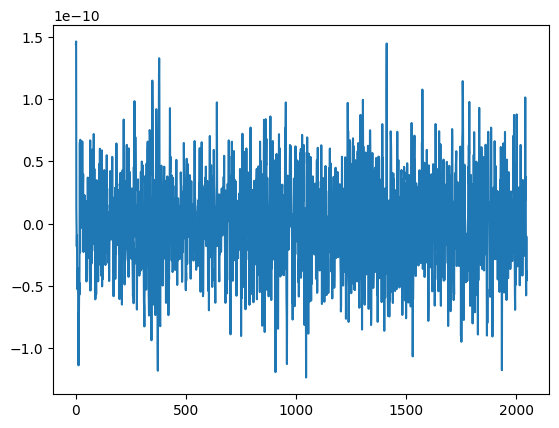

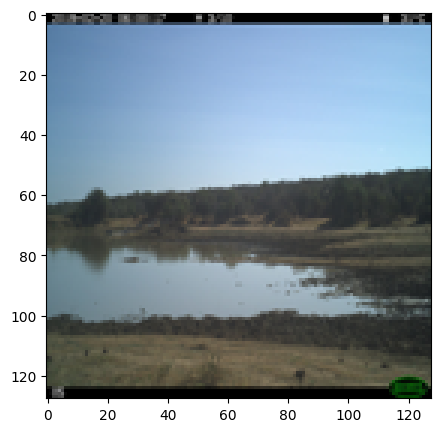

In [9]:
i_chunk = 1251
plt.figure()
plt.plot(dset["chunk"][i_chunk,0,:])
plt.figure(figsize=(5,5))
plt.imshow(dset["image"][i_chunk,:,:,:])

# Data windowing

In [13]:
time_series = dset["chunk"][i_chunk,0,:]

def windows(data, windows_size , overlap, overlapping_value):
    statistics_matrix = None
    if overlap == True:
        if overlapping_value < 1 or overlapping_value > windows_size:
            print(f"overlap value must be 1 and {windows_size}.")
        else:
            statistics_list = []
            for i in range(0, len(data) - windows_size + 1, overlapping_value):
                window = data[i:i + windows_size]
                min_val = np.min(window)
                max_val = np.max(window)
                mean = np.mean(window)
                std = np.std(window)

                statistics_list.append([min_val, max_val, mean, std])

            statistics_matrix = np.array(statistics_list)
            # print(statistics_matrix) # testing
                
                
    else:
        statistics_list = []
        for i in range(0, len(time_series) , windows_size):
            window = time_series[i:i + windows_size]
            min_val = np.min(window)
            max_val = np.max(window)
            mean = np.mean(window)
            std = np.std(window)
            statistics_list.append([min_val, max_val, mean, std])
            
            # print(f"Window {i}: {window}, Mean: {mean}, Standard deviation: {std}") # testing
        # print(statistics_list) # testing

        statistics_matrix = np.array(statistics_list)
        
        # print(statistics_matrix) # testing
    return statistics_matrix        



wsize = int(input("Enter Window size: "))
overlapping = input("is the windowing overllapping? (yes/no): ").strip().lower()
if overlapping == "yes":
    overlap = True
elif overlapping == "no":
    overlap = False
else:
    print("Yes or no olny")
    overlap = None
if overlap == True:
    overlapping_value = int(input("Enter the overlapping value :"))
else:
    overlapping_value = None

statistics_matrix = windows(time_series, wsize, overlap, overlapping_value)



Enter Window size:  200
is the windowing overllapping? (yes/no):  no


### Windowing Function

In [14]:
def windows(data, windows_size , overlap, overlapping_value):
    statistics_matrix = None
    if overlap == True:
        if overlapping_value < 1 or overlapping_value > windows_size:
            print(f"overlap value must be 1 and {windows_size}.")
        else:
            statistics_list = []
            for i in range(0, len(data) - windows_size + 1, overlapping_value):
                window = data[i:i + windows_size]
                min_val = np.min(window)
                max_val = np.max(window)
                mean = np.mean(window)
                std = np.std(window)

                statistics_list.append([min_val, max_val, mean, std])

            statistics_matrix = np.array(statistics_list)
            # print(statistics_matrix) # testing
                
                
    else:
        statistics_list = []
        for i in range(0, len(time_series) , windows_size):
            window = time_series[i:i + windows_size]
            min_val = np.min(window)
            max_val = np.max(window)
            mean = np.mean(window)
            std = np.std(window)
            statistics_list.append([min_val, max_val, mean, std])
            
            # print(f"Window {i}: {window}, Mean: {mean}, Standard deviation: {std}") # testing
        # print(statistics_list) # testing

        statistics_matrix = np.array(statistics_list)
        
        # print(statistics_matrix) # testing
    return statistics_matrix        



In [15]:
statistics_matrix

array([[-1.1390861e-10,  1.4643450e-10, -1.9500906e-13,  3.6300483e-11],
       [-1.1821159e-10,  1.3294650e-10, -8.0895848e-14,  4.2821802e-11],
       [-7.3565008e-11,  9.2850651e-11,  5.6319999e-13,  2.8172237e-11],
       [-9.0328821e-11,  9.7461240e-11, -1.5879374e-13,  3.2892116e-11],
       [-1.1932993e-10,  9.7430605e-11, -4.9176353e-13,  3.9301593e-11],
       [-1.2365775e-10,  7.1343403e-11,  9.4671753e-13,  3.4323096e-11],
       [-8.5126524e-11,  9.9507159e-11, -2.8816888e-13,  4.0607791e-11],
       [-1.0669021e-10,  1.4479304e-10,  1.0287226e-13,  3.7763688e-11],
       [-9.4971718e-11,  1.1454788e-10, -5.3979109e-13,  3.8048786e-11],
       [-1.1775633e-10,  9.3042546e-11, -3.1039540e-13,  3.6963734e-11],
       [-5.7645628e-11,  1.0144468e-10,  8.4164013e-13,  3.1693200e-11]],
      dtype=float32)

In [16]:
if statistics_matrix is not None: 
    print(f"{'Window':<10} {'Min':<10} {'Max':<10} {'Mean':<10} {'Std':<10}")
    print("-" * 100)

    for i, row in enumerate(statistics_matrix):
        window_info = f"Window {i + 1}"
        print(f"{window_info:<10} {row[0]:<10.10f} {row[1]:<10.10f} {row[2]:<10.10f} {row[3]:<10.10f}")
else:
    print("No valid statistics matrix to display.")

Window     Min        Max        Mean       Std       
----------------------------------------------------------------------------------------------------
Window 1   -0.0000000001 0.0000000001 -0.0000000000 0.0000000000
Window 2   -0.0000000001 0.0000000001 -0.0000000000 0.0000000000
Window 3   -0.0000000001 0.0000000001 0.0000000000 0.0000000000
Window 4   -0.0000000001 0.0000000001 -0.0000000000 0.0000000000
Window 5   -0.0000000001 0.0000000001 -0.0000000000 0.0000000000
Window 6   -0.0000000001 0.0000000001 0.0000000000 0.0000000000
Window 7   -0.0000000001 0.0000000001 -0.0000000000 0.0000000000
Window 8   -0.0000000001 0.0000000001 0.0000000000 0.0000000000
Window 9   -0.0000000001 0.0000000001 -0.0000000000 0.0000000000
Window 10  -0.0000000001 0.0000000001 -0.0000000000 0.0000000000
Window 11  -0.0000000001 0.0000000001 0.0000000000 0.0000000000


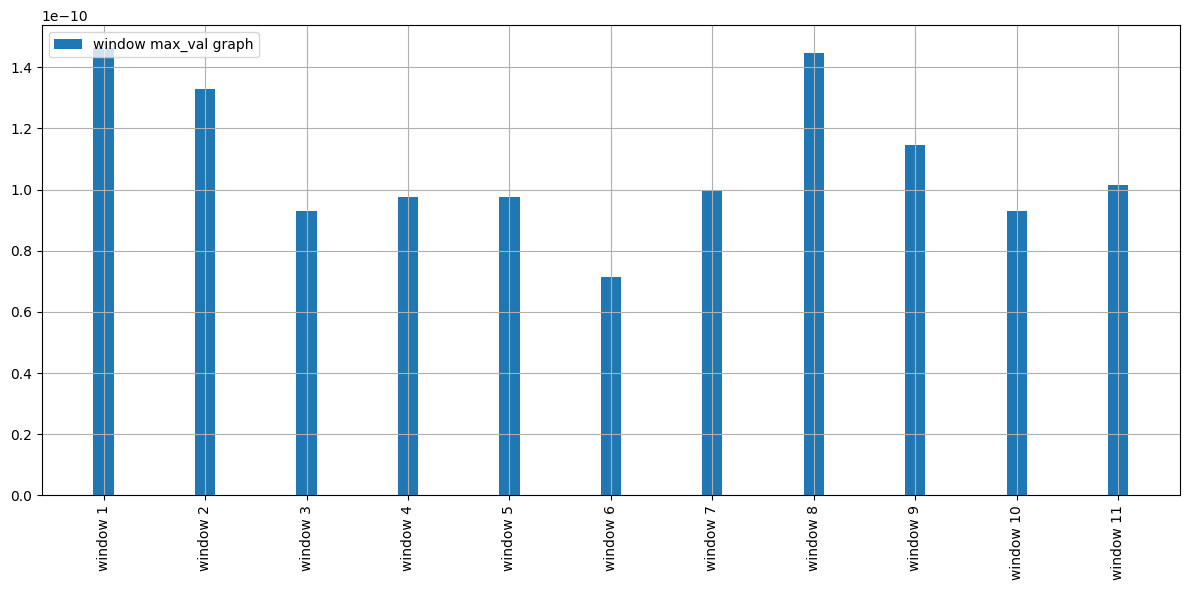

['window 1', 'window 2', 'window 3', 'window 4', 'window 5', 'window 6', 'window 7', 'window 8', 'window 9', 'window 10', 'window 11'] [1.464345e-10, 1.329465e-10, 9.285065e-11, 9.746124e-11, 9.7430605e-11, 7.13434e-11, 9.950716e-11, 1.4479304e-10, 1.1454788e-10, 9.3042546e-11, 1.0144468e-10]


In [17]:
no_windows = len(statistics_matrix)
x = []
for i in range(no_windows):
    x.append('window ' + str(i+1))

# print(x) # testing
y = [window[1] for window in statistics_matrix]

plt.figure(figsize = (12,6))
plt.bar(x, y, width = 0.2, label = 'window max_val graph')
plt.xticks(rotation = 90)
plt.legend(loc = 'upper left')
plt.grid(True)

plt.tight_layout()
plt.show()

print(x,y)

# Visibility graph

In [18]:
def is_visible(statistics_matrix, i, j):
    # linear interpolation to check visibility
    indices = [i,j]
    max_values = [statistics_matrix[i][1], statistics_matrix[j][1]]

    # check intermediate points
    for k in range(i + 1, j):
        #interpolate
        interpolated_max_val = np.interp(k, indices, max_values)
        if statistics_matrix[k][1] >= interpolated_max_val:
            return False

    return True
    

In [19]:
# garph making
G = nx.Graph()
for i in range(statistics_matrix.shape[0]):
    for j in range(i+1,statistics_matrix.shape[0]):
        # i, j = 2, 4
        visible = is_visible(statistics_matrix, i, j)
        if visible:
            G.add_edge(i, j)
        # print(f"Window {i} and Window {j} are {'visible' if visible else 'not visible'}.")
        # print(f"{i} {j} {'1' if visible else '0'}.")

In [20]:
# Visualize the visibility graph
plt.figure(figsize=(10, 6))
# pos = {i: (i, nodes[i]) for i in range(statistics_matrix.shape[0])}  # Map nodes to (x, y) positions
nx.draw(
    G,
    # pos,
    with_labels=True,
    node_color="lightblue",
    edge_color="gray",
    node_size=500,
    font_size=8,
)
plt.xlabel("Index (Flattened)")
plt.ylabel("Value")
plt.grid(True)
plt.show()

TypeError: '_AxesStack' object is not callable

<Figure size 1000x600 with 0 Axes>

# graph embedding

In [21]:
# 14/03/2025
import networkx as nx
import numpy as np
import os
from tqdm import tqdm

# Create sample graphs
def create_graphs(G,num_graphs=10, num_nodes=5):
    graphs = []
    for i in range(num_graphs):
        nx.set_node_attributes(G, {n: {"label": str(n)} for n in G.nodes()})  # Add node labels
        graphs.append(G)
    return graphs

# Generate dataset
graphs = create_graphs(G)


In [22]:
graphs = [G]

In [23]:
import numpy
import scipy
import sklearn
import pandas

print("OK")

OK


In [24]:
from karateclub import Graph2Vec
model = Graph2Vec(dimensions=128, wl_iterations=5, min_count=1, workers=1)
model.fit(graphs)

In [25]:
# Get the embedding
graph_embedding = model.get_embedding()

print("Graph embedding shape:", graph_embedding.shape)
print("Embedding vector:", graph_embedding[0])


Graph embedding shape: (1, 128)
Embedding vector: [ 6.3765775e-03  7.4747046e-03  6.3720373e-03 -6.1174715e-03
 -6.7728837e-03 -3.6141051e-03 -3.4182300e-03  3.6750683e-03
 -5.3194822e-03 -6.7489510e-03 -3.6903128e-03  7.7513140e-03
 -3.7187492e-03  1.1968004e-03  7.0187985e-03  3.4582978e-03
 -7.7556376e-04  7.4482383e-03 -4.7473451e-03  4.4124220e-03
  3.2190706e-03 -2.8090663e-03 -7.4487948e-04 -7.0297150e-03
  4.2079308e-05 -2.1184999e-03  7.9127932e-03 -3.7676303e-03
 -5.3939759e-03  8.9660834e-04 -6.2410464e-03 -6.3591530e-03
 -5.2337474e-03 -4.8669758e-03 -3.4712020e-03 -1.5675478e-03
 -1.9822351e-03  4.6038581e-03  5.4556411e-03 -3.6204029e-03
 -5.0640074e-03  6.2284333e-04 -3.5996856e-03  2.0624726e-05
  5.7291053e-03  3.1009831e-03 -4.3193675e-03 -1.0242311e-03
  1.4605084e-04 -6.4524650e-03  7.8728497e-03  6.6384892e-03
 -2.3809986e-05  4.6701957e-03  3.5976127e-03  6.9142217e-03
  2.9142180e-03 -7.4089812e-03 -1.9571420e-03  2.8641117e-03
 -4.5724813e-04  3.9132354e-03  2.8

# tasks

## 18/02/2025

### task no.1
create a dataset 60m>=

In [28]:
t1data = nc.Dataset(r"/jupyter/aswin.vs/PROJECT/dset_allspec_150_chunks_clean.nc","r")

In [29]:
output_folder = os.path.join(os.getcwd(),'Wildlife_Classification','dset')
if not os.path.exists(output_folder):
    print('not')

not


In [30]:
output_file = os.path.join(output_folder, 'subset_distance_60m_species_elephant_giraffe.nc')
output_file_csv = os.path.join(output_folder, 'subset_distance_60m_species_elephant_giraffe.csv')

In [31]:
distance = t1data.variables['distance'][:]
cls = t1data.variables['class'][:]
chunk = t1data.variables['chunk'][:]
seis = t1data.variables['seis'][:]
image = t1data.variables['image'][:]

conditions

In [32]:
condition_1 = distance <= 60
condition_2 = np.isin(cls, [2, 7])
final_condition = condition_1 & condition_2

In [33]:
filtered_chunk = chunk[final_condition]
filtered_class = cls[final_condition]
filtered_distance = distance[final_condition]
filtered_seis = seis[final_condition]
filtered_image = image[final_condition]

In [34]:
new_dataset = nc.Dataset(output_file, 'w', format='NETCDF4')

new_dataset.createDimension('traces', filtered_chunk.shape[0])
new_dataset.createDimension('comp', filtered_chunk.shape[1])
new_dataset.createDimension('time', filtered_chunk.shape[2])
new_dataset.createDimension('side', filtered_image.shape[1])

new_chunk = new_dataset.createVariable('chunk', np.float32, ('traces', 'comp', 'time'))
new_class = new_dataset.createVariable('class', np.int64, ('traces',))
new_distance = new_dataset.createVariable('distance', np.float32, ('traces',))
new_seis = new_dataset.createVariable('seis', np.int64, ('traces',))
new_image = new_dataset.createVariable('image', np.int64, ('traces', 'side', 'side', 'comp'))

new_chunk[:] = filtered_chunk
new_class[:] = filtered_class
new_distance[:] = filtered_distance
new_seis[:] = filtered_seis
new_image[:] = filtered_image


PermissionError: [Errno 13] Permission denied: '/jupyter/aswin.vs/Wildlife_Classification/dset/subset_distance_60m_species_elephant_giraffe.nc'

In [ ]:
f = nc.Dataset(output_file,'r')

In [ ]:
f

# Saving the dataset of Elephant and Giraffe

In [ ]:
long_dset = nc.Dataset(r"/jupyter/aswin.vs/Wildlife_Classification/dset_allspec_150/dset_allspec_150_chunks_clean.nc", "r")

data_list = []

for i_chunk, chunk in enumerate(long_dset["chunk"]):
    category = long_dset["class"][i_chunk]
    distance = long_dset["distance"][i_chunk]

    if distance < 60.0 and (category == 1 or category == 6):
        data_list.append(np.concatenate([chunk[0].data, [category, distance]]))

col1 = [f"t{i}" for i in range(2048)]
col = col1 + ["category", "distance"]
data = pd.DataFrame(data_list, columns=col)

data["category"] = data["category"].astype(int)
data["distance"] = data["distance"].astype(float)
print("DataFrame created successfully!")
print(data.head())


In [ ]:
data.to_csv(output_file_csv)

## saving all species distance < 60

In [ ]:
long_dset = nc.Dataset(r"/jupyter/aswin.vs/Wildlife_Classification/dset_allspec_150/dset_allspec_150_chunks_clean.nc", "r")

data_list = []

for i_chunk, chunk in enumerate(long_dset["chunk"]):
    category = long_dset["class"][i_chunk]
    distance = long_dset["distance"][i_chunk]
    
    if distance < 60.0:
        data_list.append(np.concatenate([chunk[0].data, [category, distance]))

col1 = [f"t{i}" for i in range(2048)]
col = col1 + ["category", "distance"]
data = pd.DataFrame(data_list, columns=col)

data["category"] = data["category"].astype(int)
data["distance"] = data["distance"].astype(float)
print("DataFrame created successfully!")
# print(data.head())
# data.to_csv('/jupyter/aswin.vs/Wildlife_Classification/dset/subset_distance_60m_all_species.csv')

## Read csv

In [ ]:
# pandas
start_time = time.time()
df = pd.read_csv('./Wildlife_Classification/dset/subset_distance_60m_species_elephant_giraffe.csv')
pandas_time = time.time() - start_time
print(f"{df.head()}  {pandas_time}")

In [ ]:
# polars
start_time = time.time()
df = pl.read_csv('./Wildlife_Classification/dset/subset_distance_60m_species_elephant_giraffe.csv')
polars_time = time.time() - start_time
print(f"{df.head()}  {polars_time}")

In [ ]:
#duckdb
import duckdb
start_time = time.time()
df = duckdb.sql("SELECT * FROM read_csv_auto('./Wildlife_Classification/dset/subset_distance_60m_species_elephant_giraffe.csv')").df()
duckdb_time = time.time() - start_time
print(f"{df.head()}  {duckdb_time}")

In [ ]:
!pip install duckdb


In [ ]:
import polars as pl
import time

In [ ]:
num_rows = 10
time_series_length = 2048
df = data
data_ts = df.iloc[:num_rows, :time_series_length]  # Extract time series data
labels = df.iloc[:num_rows, time_series_length:]  # Extract distance and category

fig, axes = plt.subplots(num_rows, 1, figsize=(10, 20), sharex=True)

for i, ax in enumerate(axes):
    ax.plot(data_ts.columns, data_ts.iloc[i], label=f'Row {i}')
    ax.set_title(f"Category: {labels.iloc[i, 0]}, Distance: {labels.iloc[i, 1]}")
    ax.legend()

plt.xlabel("Time Step")
plt.tight_layout()
plt.show()

In [ ]:
filtered_df = data[data["category"] == 6]
# print(filtered_df)
# print(filtered_df.count())

num_rows = 10
time_series_length = 2048
df = filtered_df
data_ts = df.iloc[:num_rows, :time_series_length]  # Extract time series data
labels = df.iloc[:num_rows, time_series_length:]  # Extract distance and category

fig, axes = plt.subplots(num_rows, 1, figsize=(10, 20), sharex=True)

for i, ax in enumerate(axes):
    ax.plot(data_ts.columns, data_ts.iloc[i], label=f'Row {i}')
    ax.set_title(f"Category: {labels.iloc[i, 0]}, Distance: {labels.iloc[i, 1]}")
    ax.legend()

plt.xlabel("Time Step")
plt.tight_layout()
plt.show()

In [ ]:
output_folder = os.path.join(os.getcwd(),'Wildlife_Classification','dset')
if not os.path.exists(output_folder):
    print('not')
output_file = os.path.join(output_folder, 'subset_distance_60m_species_elephant_giraffe.nc')
output_file_csv = os.path.join(output_folder, 'subset_distance_60m_species_elephant_giraffe.csv')

In [ ]:
# saving the dataframe
if data.empty or output_file_csv:
    print("The DataFrame is empty or the file already exist. No data to save.")
else:
    data.to_csv(output_file_csv, index=False)
    print("Data saved successfully.")


## windowing category 1

In [ ]:
# def windows(data, windows_size , overlap, overlapping_value):
time_series = data_ts.iloc[0]
w_size = int(input("Enter Window size: "))
overlapping = input("is the windowing overllapping? (yes/no): ").strip().lower()
if overlapping == "yes":
    overlap = True
elif overlapping == "no":
    overlap = False
else:
    print("Yes or no olny")
    overlap = None
if overlap == True:
    overlapping_value = int(input("Enter the overlapping value :"))
else:
    overlapping_value = None
window = windows(data_ts.iloc[0], w_size, overlap, overlapping_value)

In [ ]:
print(window)

In [ ]:
if window is not None: 
    print(f"{'Window':<10} {'Min':<10} {'Max':<10} {'Mean':<10} {'Std':<10}")
    print("-" * 100)

    for i, row in enumerate(window):
        window_info = f"Window {i + 1}"
        print(f"{window_info:<10} {row[0]:<10.10f} {row[1]:<10.10f} {row[2]:<10.10f} {row[3]:<10.10f}")
else:
    print("No valid statistics matrix to display.")

In [ ]:
no_windows = len(window)
x = []
for i in range(no_windows):
    x.append('window ' + str(i+1))

# print(x) # testing
y = [window[1] for window in window]

plt.figure(figsize = (12,6))
plt.bar(x, y, width = 0.2, label = 'window max_val graph')
plt.xticks(rotation = 90)
plt.legend(loc = 'upper left')
plt.grid(True)

plt.tight_layout()
plt.show()

print(x,y)

### visibility graph

In [ ]:
G = nx.Graph()
for i in range(window.shape[0]):
    for j in range(i+1,window.shape[0]):
        # i, j = 2, 4
        visible = is_visible(window, i, j)
        if visible:
            G.add_edge(i, j)
        print(f"Window {i} and Window {j} are {'visible' if visible else 'not visible'}.")
        print(f"{i} {j} {'1' if visible else '0'}.")

In [ ]:
print("Nodes:", G.nodes())
print("Edges:", G.edges())


In [ ]:
!/cm/local/apps/python39/bin/python3 -m pip install --upgrade pip

In [ ]:
# from networkx import *
# Visualize the visibility graph
fig, ax =plt.subplots(figsize=(6, 4))
# pos = {i: (i, nodes[i]) for i in range(window.shape[0])}  # Map nodes to (x, y) positions
pos = nx.spring_layout(G, seed=42)  # Spring layout for better spacing
nx.draw(
    G,
    ax=ax,
    pos=pos,
    with_labels=True,
    node_color="lightblue",
    edge_color="gray",
    node_size=5000,
    font_size=8,
)
# plt.title("Visibility Graph from Min and Max Values in Time Series Windows")
# plt.xlabel("Index (Flattened)")
# plt.ylabel("Value")
# plt.grid(True)
plt.show()

In [ ]:
import pickle
with open('Graph_List_Class1.pkl', 'wb') as f:
    pickle.dump(G, f)

In [ ]:
import pickle
with open('Graph_List.pkl', 'rb') as f:
    G = pickle.load(f)  # Load the object from the file

In [ ]:
import matplotlib.pyplot as plt
import networkx as nx
plt.figure(figsize=(8, 8))
pos = nx.spring_layout(G[1])
nx.draw(G[1], pos, node_size=10, node_color='c', edge_color='gray')
plt.title("Visibility Graph of the Noise Signal")
plt.show()

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt

# Create a sample graph
G = nx.Graph()
G.add_edges_from([(1, 2), (2, 3), (3, 1), (3, 4)])

# Create figure and axes explicitly
fig, ax = plt.subplots(figsize=(6, 4))

# Use a layout to avoid overlapping nodes
pos = nx.spring_layout(G)

# Draw graph inside the given axes
nx.draw(G, pos, ax=ax, with_labels=True, node_color="lightblue", edge_color="gray", node_size=2000, font_size=10)

plt.show()



In [ ]:
import networkx as nx
import plotly.graph_objects as go

pos = nx.spring_layout(G)  # Position nodes using spring layout
edge_x, edge_y = [], []

# Extract edges
for edge in G.edges():
    x0, y0 = pos[edge[0]]
    x1, y1 = pos[edge[1]]
    edge_x.extend([x0, x1, None])
    edge_y.extend([y0, y1, None])

edge_trace = go.Scatter(x=edge_x, y=edge_y, mode='lines', line=dict(width=1, color='gray'))

node_x, node_y = zip(*pos.values())

node_trace = go.Scatter(
    x=node_x, y=node_y, mode='markers+text',
    text=[str(node) for node in G.nodes()],
    marker=dict(size=10, color='blue'),
    textposition="top center"
)

fig = go.Figure(data=[edge_trace, node_trace])
fig.show()


In [ ]:
pip install plotly
